# Benchmark (RDD) Models


## 1. Environment

In [11]:
import csv
import gc
import json
import sys
import time
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple

import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.image as mpimg
import numpy as np
import torch
import torch.nn as nn
import torchvision.ops
import yaml

from ultralytics import YOLO
from ultralytics.nn import tasks, modules
from ultralytics.nn.modules import Conv, Detect
from ultralytics.utils.torch_utils import get_flops

# -------------------------------------------------------------
# Dataset Constants (P25 RDD Dataset - 4 Classes)
# -------------------------------------------------------------
CLASS_NAMES = ['D00', 'D10', 'D20', 'D40']
CLASS_LABELS = {
    'D00': 'Longitudinal Crack',
    'D10': 'Transverse Crack',
    'D20': 'Alligator Crack',
    'D40': 'Pothole',
}
CLASS_COLORS = {
    'D00': (46, 204, 113),   # Green (RGB)
    'D10': (52, 152, 219),   # Blue (RGB)
    'D20': (231, 76, 60),    # Red (RGB)
    'D40': (243, 156, 18),   # Amber/Orange (RGB)
}

# -------------------------------------------------------------
# P26 Custom Architectural Modules (YOLO-DGVG Methodology)
# Supports native CPU and CUDA GPU execution
# -------------------------------------------------------------
class DeformConv2d(nn.Module):
    def __init__(self, inc: int, outc: int, kernel_size: int = 3, padding: int = 1, stride: int = 1, bias: Optional[bool] = None):
        super().__init__()
        self.stride = stride
        self.padding = padding
        self.conv_offset = nn.Conv2d(inc, 3 * kernel_size * kernel_size, kernel_size=kernel_size, stride=stride, padding=padding, bias=True)
        nn.init.constant_(self.conv_offset.weight, 0.0)
        nn.init.constant_(self.conv_offset.bias, 0.0)
        self.weight = nn.Parameter(torch.empty(outc, inc, kernel_size, kernel_size))
        nn.init.kaiming_uniform_(self.weight, a=1)
        if bias:
            self.bias = nn.Parameter(torch.zeros(outc))
        else:
            self.register_parameter('bias', None)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        orig_dtype = x.dtype
        x_f = x.float().contiguous(memory_format=torch.contiguous_format)
        out = self.conv_offset(x_f)
        o1, o2, mask = torch.chunk(out, 3, dim=1)
        offset = torch.cat((o1, o2), dim=1).contiguous(memory_format=torch.contiguous_format)
        offset = torch.nan_to_num(offset, nan=0.0, posinf=10.0, neginf=-10.0)
        mask = torch.nan_to_num(torch.sigmoid(mask), nan=0.5).contiguous(memory_format=torch.contiguous_format)
        w_f = self.weight.float().contiguous(memory_format=torch.contiguous_format)
        b_f = self.bias.float().contiguous(memory_format=torch.contiguous_format) if self.bias is not None else None
        try:
            res = torchvision.ops.deform_conv2d(
                input=x_f, offset=offset, weight=w_f, bias=b_f,
                stride=(self.stride, self.stride), padding=(self.padding, self.padding), mask=mask
            )
        except Exception:
            res = nn.functional.conv2d(x_f, w_f, b_f, stride=self.stride, padding=self.padding)
        return res.to(orig_dtype)

class Bottleneck_DCNv2(nn.Module):
    def __init__(self, c1: int, c2: int, shortcut: bool = True, g: int = 1, k: Tuple[int, int] = (3, 3), e: float = 0.5):
        super().__init__()
        c_ = int(c2 * e)
        self.cv1 = Conv(c1, c_, k[0], 1)
        self.dcn = DeformConv2d(c_, c2, k[1], 1, padding=k[1] // 2)
        self.bn = nn.BatchNorm2d(c2)
        self.act = nn.SiLU()
        self.add = shortcut and c1 == c2

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = self.act(self.bn(self.dcn(self.cv1(x))))
        return x + out if self.add else out

class C2f_DCNv2(nn.Module):
    def __init__(self, c1: int, c2: int, n: int = 1, shortcut: bool = False, g: int = 1, e: float = 0.5):
        super().__init__()
        self.c = int(c2 * e)
        self.cv1 = Conv(c1, 2 * self.c, 1, 1)
        self.cv2 = Conv((2 + n) * self.c, c2, 1)
        self.m = nn.ModuleList(Bottleneck_DCNv2(self.c, self.c, shortcut, g, k=(3, 3), e=1.0) for _ in range(n))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        y = list(self.cv1(x).chunk(2, 1))
        y.extend(m(y[-1]) for m in self.m)
        return self.cv2(torch.cat(y, 1))

class GSConv(nn.Module):
    def __init__(self, c1: int, c2: int, k: int = 1, s: int = 1, g: int = 1, act: bool = True):
        super().__init__()
        c_ = c2 // 2
        self.cv1 = Conv(c1, c_, k, s, None, g, act=act)
        self.cv2 = Conv(c_, c_, 5, 1, None, c_, act=act)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x1 = self.cv1(x)
        x2 = self.cv2(x1)
        b, c, h, w = x1.shape
        out = torch.cat((x1, x2), dim=1)
        out = out.view(b, 2, c, h, w).transpose(1, 2).contiguous().view(b, c * 2, h, w)
        return out

class GSBottleneck(nn.Module):
    def __init__(self, c1: int, c2: int, k: int = 3, s: int = 1, e: float = 0.5):
        super().__init__()
        c_ = int(c2 * e)
        self.conv1 = GSConv(c1, c_, 1, 1)
        self.conv2 = GSConv(c_, c2, 3, 1)
        self.shortcut = c1 == c2

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.conv2(self.conv1(x)) if self.shortcut else self.conv2(self.conv1(x))

class VoVGSCSP(nn.Module):
    def __init__(self, c1: int, c2: int, n: int = 1, shortcut: bool = True, g: int = 1, e: float = 0.5):
        super().__init__()
        c_ = int(c2 * e)
        self.cv1 = Conv(c1, c_, 1, 1)
        self.cv2 = Conv(2 * c_, c2, 1, 1)
        self.m = nn.Sequential(*(GSBottleneck(c_, c_, e=1.0) for _ in range(n)))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x1 = self.cv1(x)
        return self.cv2(torch.cat((self.m(x1), x1), dim=1))

class GCHDetect(Detect):
    def __init__(self, nc: int = 80, reg_max: int = 16, end2end: bool = False, ch: Tuple[int, ...] = ()):
        super().__init__(nc, reg_max, end2end, ch)
        c_mid = max(16, ch[0] // 4, self.reg_max * 4)
        g = 4
        self.shared = nn.ModuleList(
            nn.Sequential(
                Conv(x, c_mid, 3, g=min(g, x, c_mid)),
                Conv(c_mid, c_mid, 3, g=min(g, c_mid)),
            ) for x in ch
        )
        self.cv2 = nn.ModuleList(nn.Sequential(nn.Conv2d(c_mid, 4 * self.reg_max, 1)) for _ in ch)
        self.cv3 = nn.ModuleList(nn.Sequential(nn.Conv2d(c_mid, self.nc, 1)) for _ in ch)

    def forward_head(self, x: List[torch.Tensor], box_head=None, cls_head=None) -> Dict[str, Any]:
        bs = x[0].shape[0]
        feats = [self.shared[i](x[i]) for i in range(self.nl)]
        boxes = torch.cat([self.cv2[i](feats[i]).view(bs, 4 * self.reg_max, -1) for i in range(self.nl)], dim=-1)
        scores = torch.cat([self.cv3[i](feats[i]).view(bs, self.nc, -1) for i in range(self.nl)], dim=-1)
        return {'boxes': boxes, 'scores': scores, 'feats': x}

def register_p26_modules():
    p26_classes = [DeformConv2d, Bottleneck_DCNv2, C2f_DCNv2, GSConv, GSBottleneck, VoVGSCSP, GCHDetect]
    main_mod = sys.modules.get('__main__')
    for cls in p26_classes:
        if main_mod:
            setattr(main_mod, cls.__name__, cls)
        setattr(tasks, cls.__name__, cls)
        setattr(modules, cls.__name__, cls)
        if hasattr(tasks, 'torch') and hasattr(tasks.torch, 'nn'):
            setattr(tasks.torch.nn, cls.__name__, cls)
    if hasattr(torch, 'serialization') and hasattr(torch.serialization, 'add_safe_globals'):
        try:
            torch.serialization.add_safe_globals(p26_classes)
        except Exception:
            pass

register_p26_modules()

def clear_hardware_cache():
    '''Release GPU and MPS unified memory.'''
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if hasattr(torch, 'mps') and torch.backends.mps.is_available():
        try:
            torch.mps.empty_cache()
        except Exception:
            pass

# Automatic compute device selection
if torch.cuda.is_available():
    DEVICE = 'cuda:0'
elif torch.backends.mps.is_available():
    DEVICE = 'mps'
else:
    DEVICE = 'cpu'

# Multi-platform path resolver for Local, Kaggle, or Google Colab
def resolve_path(name: str, candidate_dirs: List[Path]) -> Path:
    for base in candidate_dirs:
        candidate = base / name
        if candidate.exists():
            return candidate
    return candidate_dirs[0] / name

_cwd = Path('.').resolve()
if (_cwd / 'model').exists() and (_cwd / 'dataset').exists():
    PROJECT_ROOT = _cwd
elif (_cwd.parent / 'model').exists() and (_cwd.parent / 'dataset').exists():
    PROJECT_ROOT = _cwd.parent
else:
    PROJECT_ROOT = _cwd

BENCHMARK_DIR = PROJECT_ROOT / 'benchmark'
BENCHMARK_DIR.mkdir(parents=True, exist_ok=True)

search_bases = [
    PROJECT_ROOT,
    _cwd,
    Path('/kaggle/working'),
    Path('/kaggle/input/ail-rdd'),
    Path('/kaggle/input/road-damage-dataset'),
]
MODEL_DIR = resolve_path('model', search_bases)
DATASET_DIR = resolve_path('dataset', search_bases)

# Locate model checkpoints
target_models = sorted(list(MODEL_DIR.glob('*.pt')))

print(f'Compute Device: {DEVICE}')
print(f'Project Root:   {PROJECT_ROOT}')
print(f'Model Dir:      {MODEL_DIR} (Found {len(target_models)} models)')
print(f'Dataset Dir:    {DATASET_DIR}')
print('P26 modules registered successfully.')


Compute Device: cpu
Project Root:   /Users/trietnguyen/Documents/AIL-RDD
Model Dir:      /Users/trietnguyen/Documents/AIL-RDD/model (Found 4 models)
Dataset Dir:    /Users/trietnguyen/Documents/AIL-RDD/dataset
P26 modules registered successfully.


## 2. Model Architecture & Pipeline


In [12]:
class YOLOv26nPipeline:
    '''End-to-end inference pipeline for yolov26n_best.pt.'''
    def __init__(self, model_path: Path, device: str = 'cpu'):
        self.model_path = Path(model_path)
        self.device = device
        if not self.model_path.exists():
            raise FileNotFoundError(f'Checkpoint not found: {self.model_path}')
        self.model = YOLO(str(self.model_path))

    def predict(
        self,
        image_input: Any,
        conf_threshold: float = 0.25,
        iou_threshold: float = 0.45,
        imgsz: int = 640,
    ) -> Dict[str, Any]:
        '''Execute inference and benchmark per-stage execution latency.'''
        start_time = time.perf_counter()
        results = self.model.predict(
            source=image_input,
            conf=conf_threshold,
            iou=iou_threshold,
            imgsz=imgsz,
            device=self.device,
            verbose=False,
        )
        total_time_ms = (time.perf_counter() - start_time) * 1000.0
        res = results[0]
        speed_info = res.speed  # preprocess, inference, postprocess

        detections = []
        if res.boxes is not None and len(res.boxes) > 0:
            boxes = res.boxes.xyxy.cpu().numpy()
            confs = res.boxes.conf.cpu().numpy()
            classes = res.boxes.cls.cpu().numpy().astype(int)
            for box, conf, cls_id in zip(boxes, confs, classes):
                cls_name = CLASS_NAMES[cls_id] if cls_id < len(CLASS_NAMES) else f'cls_{cls_id}'
                detections.append({
                    'class_id': int(cls_id),
                    'class_name': cls_name,
                    'description': CLASS_LABELS.get(cls_name, ''),
                    'confidence': float(conf),
                    'bbox': [float(x) for x in box],
                })

        return {
            'orig_image': res.orig_img,
            'detections': detections,
            'count': len(detections),
            'speed': speed_info,
            'total_time_ms': total_time_ms,
            'fps': round(1000.0 / total_time_ms, 1) if total_time_ms > 0 else 0.0,
        }

    def visualize_prediction(
        self,
        pred_result: Dict[str, Any],
        title: str = 'YOLOv26n Detection Result',
        figsize: Tuple[int, int] = (10, 8),
    ) -> None:
        '''Render annotated bounding boxes with class colors and latency header.'''
        img_bgr = pred_result['orig_image'].copy()
        for det in pred_result['detections']:
            x1, y1, x2, y2 = [int(v) for v in det['bbox']]
            cname = det['class_name']
            conf = det['confidence']
            rgb_color = CLASS_COLORS.get(cname, (0, 255, 0))
            bgr_color = (rgb_color[2], rgb_color[1], rgb_color[0])
            cv2.rectangle(img_bgr, (x1, y1), (x2, y2), bgr_color, 2)
            label_text = f'{cname}: {conf:.2f}'
            (tw, th), _ = cv2.getTextSize(label_text, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 1)
            cv2.rectangle(img_bgr, (x1, max(0, y1 - 22)), (x1 + tw + 4, max(0, y1)), bgr_color, -1)
            cv2.putText(img_bgr, label_text, (x1 + 2, max(0, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1, cv2.LINE_AA)

        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=figsize)
        plt.imshow(img_rgb)
        speed_str = f'Inference: {pred_result["speed"].get("inference", 0.0):.1f}ms | Total: {pred_result["total_time_ms"]:.1f}ms ({pred_result["fps"]} FPS)'
        plt.title(f'{title} ({pred_result["count"]} detections)\n{speed_str}', fontsize=12)
        plt.axis('off')
        plt.tight_layout()
        plt.show()

# Instantiate YOLOv26n pipeline
yolov26n_path = MODEL_DIR / 'yolov26n_best.pt'
if yolov26n_path.exists():
    pipeline = YOLOv26nPipeline(yolov26n_path, device=DEVICE)
    print(f'YOLOv26n pipeline initialized successfully with {yolov26n_path.name}')
else:
    print(f'Warning: Checkpoint not found at {yolov26n_path}')


YOLOv26n pipeline initialized successfully with yolov26n_best.pt


## 3. Unified Benchmark Engine

In [13]:
# -------------------------------------------------------------
# Benchmark Configuration
# -------------------------------------------------------------
SAMPLE_LIMIT = 50                 # Set None to evaluate all 3493 validation images
SPEED_SAMPLES_PER_CLASS = 15     # Number of test images per damage class
USE_CHECKPOINT_METRICS = False    # Set True to load pre-calculated checkpoint metadata

# Generate dataset configuration yaml
DATA_YAML = PROJECT_ROOT / 'rdd2022_local.yaml'
data_config = {
    'path': str(DATASET_DIR.resolve()),
    'train': 'train/images',
    'val': 'val/images',
    'test': 'test/images',
    'nc': 4,
    'names': CLASS_NAMES,
}
with open(DATA_YAML, 'w') as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

# Index validation images by defect category
def index_images_by_class(val_labels_dir: Path, val_images_dir: Path) -> Dict[str, List[Path]]:
    class_images = {c: [] for c in CLASS_NAMES}
    for lbl_file in val_labels_dir.glob('*.txt'):
        try:
            with open(lbl_file, 'r', encoding='utf-8') as f:
                lines = f.readlines()
            found_classes = set()
            for line in lines:
                parts = line.strip().split()
                if parts:
                    cid = int(float(parts[0]))
                    if 0 <= cid < len(CLASS_NAMES):
                        found_classes.add(CLASS_NAMES[cid])
            stem = lbl_file.stem
            img_path = None
            for ext in ['.jpg', '.png', '.jpeg', '.JPG', '.PNG']:
                candidate = val_images_dir / (stem + ext)
                if candidate.exists():
                    img_path = candidate
                    break
            if img_path:
                for c in found_classes:
                    class_images[c].append(img_path)
        except Exception:
            continue
    return class_images

val_lbl_dir = DATASET_DIR / 'val' / 'labels'
val_img_dir = DATASET_DIR / 'val' / 'images'
class_img_map = index_images_by_class(val_lbl_dir, val_img_dir)

def sync_hardware(device_str: str):
    '''Synchronize GPU / MPS compute streams for accurate latency timing.'''
    if 'cuda' in device_str and torch.cuda.is_available():
        torch.cuda.synchronize()
    elif device_str == 'mps' and hasattr(torch, 'mps') and torch.backends.mps.is_available():
        try:
            torch.mps.synchronize()
        except Exception:
            pass

# -------------------------------------------------------------
# Unified Benchmark Runner Function
# -------------------------------------------------------------
def run_unified_benchmark(
    model_paths: List[Path],
    data_yaml: Path,
    class_img_map: Dict[str, List[Path]],
    sample_limit: Optional[int] = 50,
    speed_samples_per_class: int = 15,
    use_checkpoint: bool = False,
    device: str = 'cpu',
    imgsz: int = 640,
) -> List[Dict[str, Any]]:
    results = []
    total_m = len(model_paths)
    print('=' * 95)
    print(f'UNIFIED BENCHMARK EXECUTION ({total_m} MODELS) - COMPUTE DEVICE: {device.upper()}')
    print('=' * 95)

    for idx, pt_path in enumerate(model_paths, start=1):
        m_name = pt_path.stem
        file_size_mb = round(pt_path.stat().st_size / (1024 * 1024), 2)
        print(f'[{idx}/{total_m}] Evaluating: {pt_path.name} ({file_size_mb} MB)...')

        model = YOLO(str(pt_path))

        # 1. Measure Parameters & GFLOPs
        total_params = sum(p.numel() for p in model.model.parameters())
        params_m = round(total_params / 1e6, 2)
        try:
            flops = float(get_flops(model.model, imgsz=imgsz))
            gflops = round(flops, 2)
        except Exception as e:
            print(f'    GFLOPs profiling notice: {e}')
            gflops = 0.0
        print(f'    Params: {params_m}M | GFLOPs: {gflops}')

        # 2. Measure Detection Accuracy (mAP@50 & per-class AP)
        acc_dict = {
            'map50': 0.0,
            'map50_95': 0.0,
            'precision': 0.0,
            'recall': 0.0,
            'ap50_per_class': {c: 0.0 for c in CLASS_NAMES},
        }
        overall_latency_ms = 0.0
        overall_fps = 0.0

        if use_checkpoint:
            try:
                ckpt = torch.load(str(pt_path), map_location='cpu')
                tm = ckpt.get('train_metrics', {})
                if tm and 'metrics/mAP50(B)' in tm:
                    acc_dict['map50'] = round(float(tm['metrics/mAP50(B)']) * 100.0, 2)
                    acc_dict['map50_95'] = round(float(tm.get('metrics/mAP50-95(B)', 0.0)) * 100.0, 2)
                    acc_dict['precision'] = round(float(tm.get('metrics/precision(B)', 0.0)) * 100.0, 2)
                    acc_dict['recall'] = round(float(tm.get('metrics/recall(B)', 0.0)) * 100.0, 2)
            except Exception as e:
                print(f'    Checkpoint metadata read notice: {e}')
        else:
            val_kwargs = {
                'data': str(data_yaml),
                'split': 'val',
                'imgsz': imgsz,
                'batch': 16,
                'device': device,
                'plots': False,
                'verbose': False,
                'save': False,
            }
            if sample_limit and sample_limit > 0:
                val_kwargs['fraction'] = [1.0, sample_limit]
                val_kwargs['cache'] = False

            val_res = model.val(**val_kwargs)
            acc_dict['map50'] = round(float(val_res.box.map50) * 100.0, 2)
            acc_dict['map50_95'] = round(float(val_res.box.map) * 100.0, 2)
            acc_dict['precision'] = round(float(val_res.box.mp) * 100.0, 2)
            acc_dict['recall'] = round(float(val_res.box.mr) * 100.0, 2)
            inf_speed = float(val_res.speed.get('inference', 0.0))
            overall_latency_ms = round(inf_speed, 1)
            overall_fps = round(1000.0 / inf_speed, 1) if inf_speed > 0 else 0.0

            if hasattr(val_res.box, 'ap50') and hasattr(val_res.box, 'ap_class_index'):
                ap_map = dict(zip(val_res.box.ap_class_index, val_res.box.ap50))
                for c_idx, cname in enumerate(CLASS_NAMES):
                    acc_dict['ap50_per_class'][cname] = round(float(ap_map.get(c_idx, 0.0)) * 100.0, 2)

        print(f"    mAP@50: {acc_dict['map50']:.2f}% | mAP50-95: {acc_dict['map50_95']:.2f}%")

        # 3. Measure Per-Class Detection Speed (Latency & FPS)
        speed_per_class = {}
        dummy = np.zeros((640, 640, 3), dtype=np.uint8)
        for _ in range(2):
            model.predict(dummy, device=device, verbose=False)

        for cname in CLASS_NAMES:
            images = class_img_map.get(cname, [])[:speed_samples_per_class]
            if not images:
                speed_per_class[cname] = {'latency_ms': 0.0, 'fps': 0.0}
                continue

            class_latencies = []
            for img_p in images:
                sync_hardware(device)
                t0 = time.perf_counter()
                preds = model.predict(str(img_p), device=device, verbose=False, imgsz=imgsz)
                sync_hardware(device)
                wall_lat = (time.perf_counter() - t0) * 1000.0
                if preds and hasattr(preds[0], 'speed'):
                    pure_lat = preds[0].speed.get('inference', 0.0) + preds[0].speed.get('postprocess', 0.0)
                    class_latencies.append(pure_lat if pure_lat > 0 else wall_lat)
                else:
                    class_latencies.append(wall_lat)

            avg_c_lat = float(np.mean(class_latencies)) if class_latencies else 0.0
            c_fps = round(1000.0 / avg_c_lat, 1) if avg_c_lat > 0 else 0.0
            speed_per_class[cname] = {
                'latency_ms': round(avg_c_lat, 2),
                'fps': c_fps,
            }

        if overall_latency_ms <= 0:
            all_lats = [speed_per_class[c]['latency_ms'] for c in CLASS_NAMES if speed_per_class[c]['latency_ms'] > 0]
            overall_latency_ms = round(float(np.mean(all_lats)), 1) if all_lats else 0.0
            overall_fps = round(1000.0 / overall_latency_ms, 1) if overall_latency_ms > 0 else 0.0

        print(f"    Avg Latency: {overall_latency_ms:.1f} ms ({overall_fps} FPS)")

        # Package entry into unified record
        entry = {
            'model_name': m_name,
            'filename': pt_path.name,
            'params_m': params_m,
            'gflops': gflops,
            'size_mb': file_size_mb,
            'map50': acc_dict['map50'],
            'map50_95': acc_dict['map50_95'],
            'precision': acc_dict['precision'],
            'recall': acc_dict['recall'],
            'ap50_per_class': acc_dict['ap50_per_class'],
            'speed_per_class': speed_per_class,
            'avg_latency_ms': overall_latency_ms,
            'avg_fps': overall_fps,
        }
        results.append(entry)

        del model
        clear_hardware_cache()
        print()

    return results

# Execute Unified Benchmark
combined_data = run_unified_benchmark(
    model_paths=target_models,
    data_yaml=DATA_YAML,
    class_img_map=class_img_map,
    sample_limit=SAMPLE_LIMIT,
    speed_samples_per_class=SPEED_SAMPLES_PER_CLASS,
    use_checkpoint=USE_CHECKPOINT_METRICS,
    device=DEVICE,
    imgsz=640,
)
print('Unified benchmark execution finished successfully.')


UNIFIED BENCHMARK EXECUTION (4 MODELS) - COMPUTE DEVICE: CPU
[1/4] Evaluating: yolo11s_best.pt (18.29 MB)...
    Params: 9.43M | GFLOPs: 21.67
Ultralytics 8.4.178 🚀 Python-3.12.14 torch-2.2.2 CPU (Intel Core i7-8569U 2.80GHz)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 191.4±74.4 MB/s, size: 86.9 KB)
val: Scanning /Users/trietnguyen/Documents/AIL-RDD/dataset/val/labels.cache... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 26.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 3.9s/it 15.4s7.5ss
                   all         50         81      0.809      0.746      0.815      0.558
Speed: 3.6ms preprocess, 294.0ms inference, 0.0ms loss, 2.3ms postprocess per image
    mAP@50: 81.49% | mAP50-95: 55.82%
    Avg Latency: 294.0 ms (3.4 FPS)

[2/4] Evaluating: yolov10s_best.pt (15.76 MB)...
    Params: 8.07M | GFLOP

## 4. Visualization

**Figure 1 (Neural Network Architecture — `f1_architecture_yolov26n.png`)**: Streamlined modular architecture diagram of YOLOv26n (C2f-DCNv2 Backbone, Slim-Neck VoVGSCSP + GSConv, and GCH Detection Head) featuring clear block hierarchy and large, readable typography.

**Figure 2 (Inference & Evaluation Pipeline — `f2_pipeline_yolov26n.png`)**: Clean, standalone end-to-end detection pipeline illustrating the 5 operational stages from input pavement imagery to post-processed damage predictions across D00, D10, D20, and D40 classes.

**Figure 3 (Core Metrics — `f3_core_metrics.png`)**: Side-by-side comparison of Parameters (M), GFLOPs, and mAP@50 (%).

**Figure 4 (Per-Class Accuracy — `f4_per_class_ap.png`)**: Grouped bar chart comparing AP@50 across D00, D10, D20, and D40.

**Figure 5 (Speed & Frame Rate — `f5_speed_comparison.png`)**: Inference latency (ms) and throughput (FPS) per damage category.

**Figure 6 (Pareto Efficiency Frontier — `f6_pareto_tradeoff.png`)**: Trade-off scatter plots analyzing accuracy vs. computational cost.

**Figure 7 (Multi-Metric Radar Chart — `f7_radar_chart.png`)**: Normalized multi-criteria evaluation of all models.


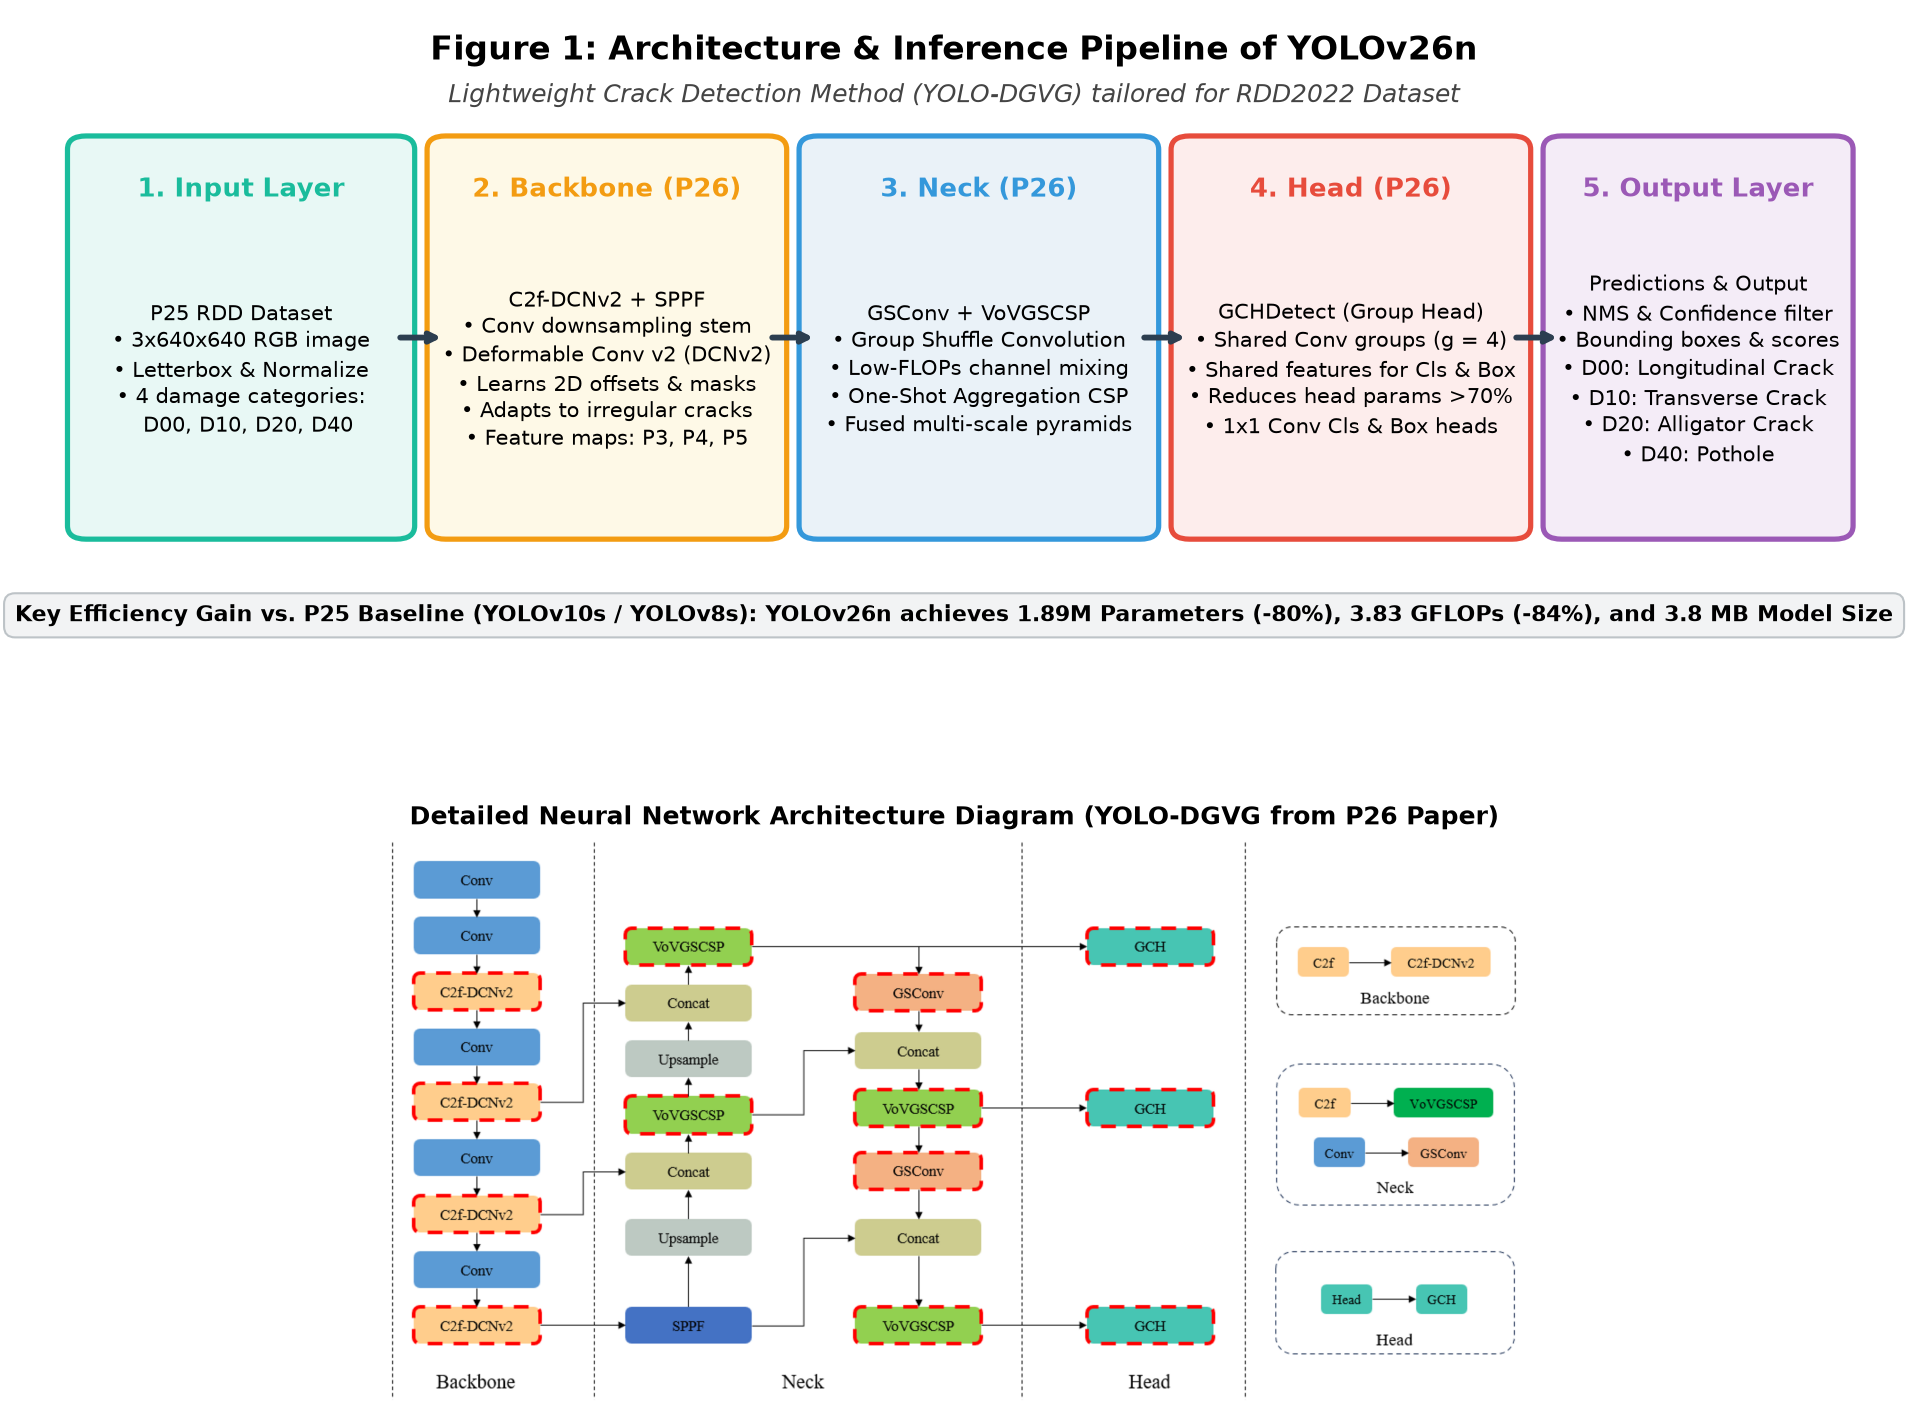

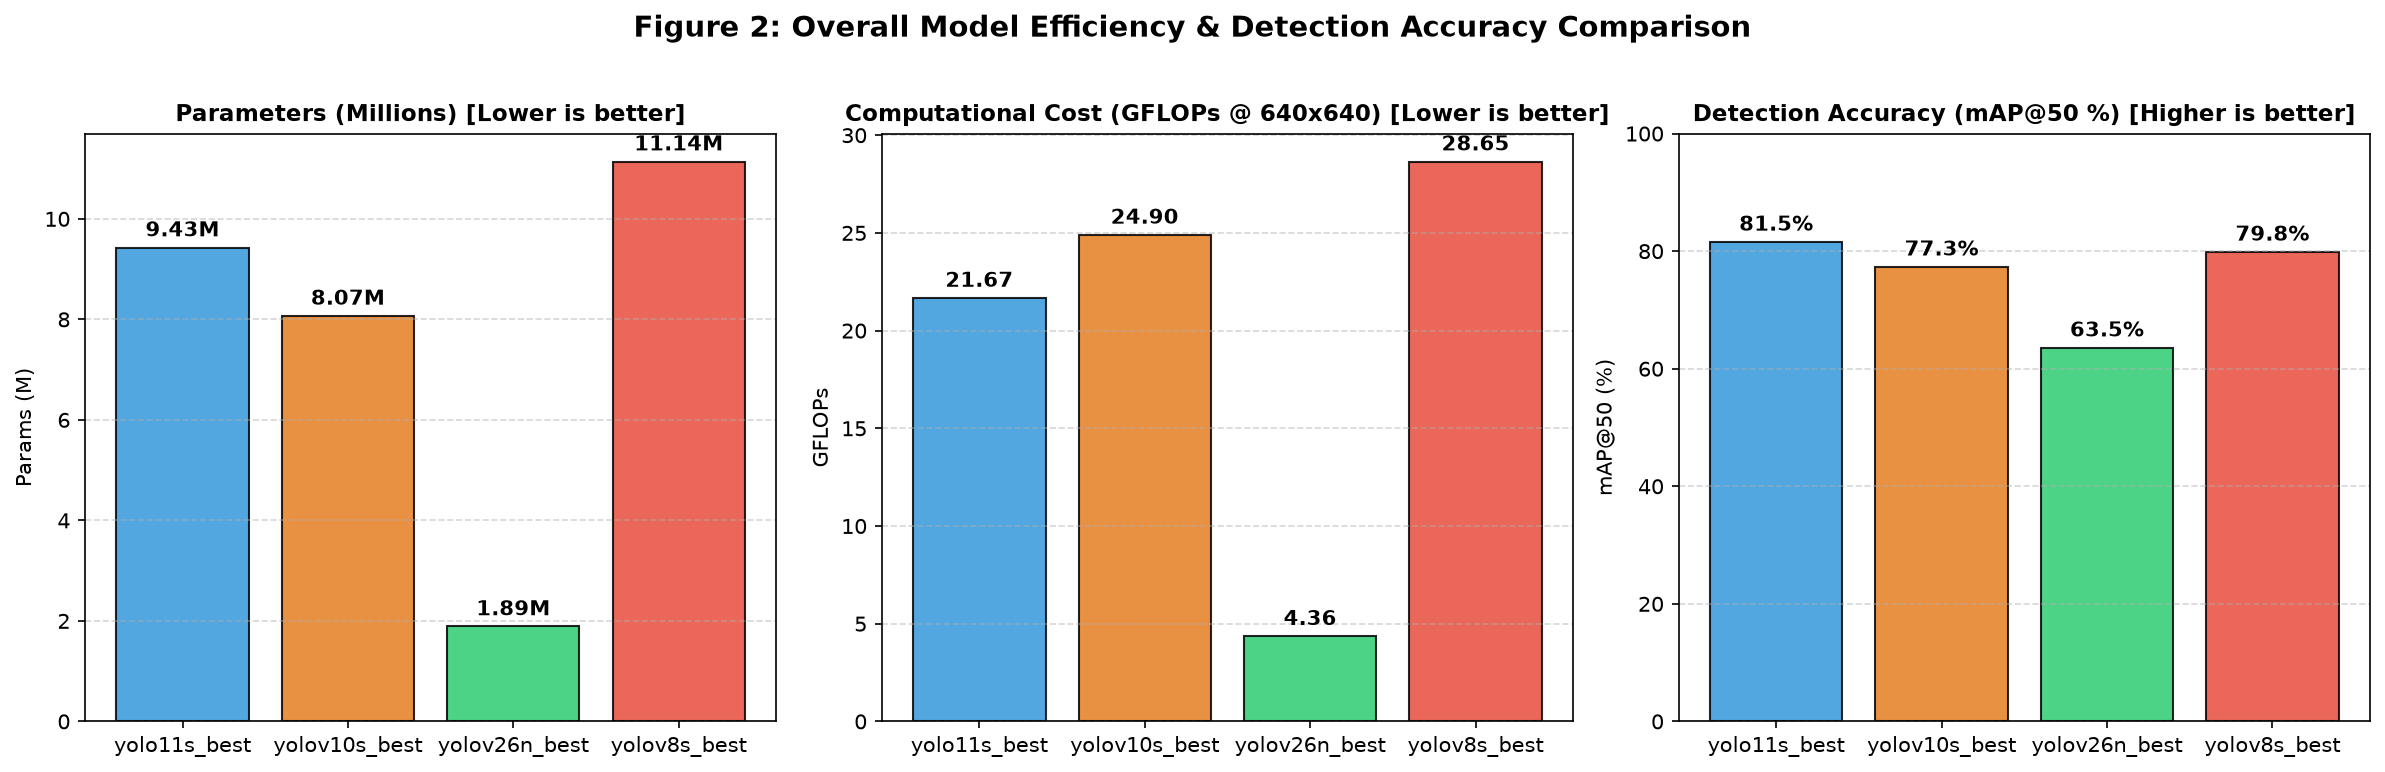

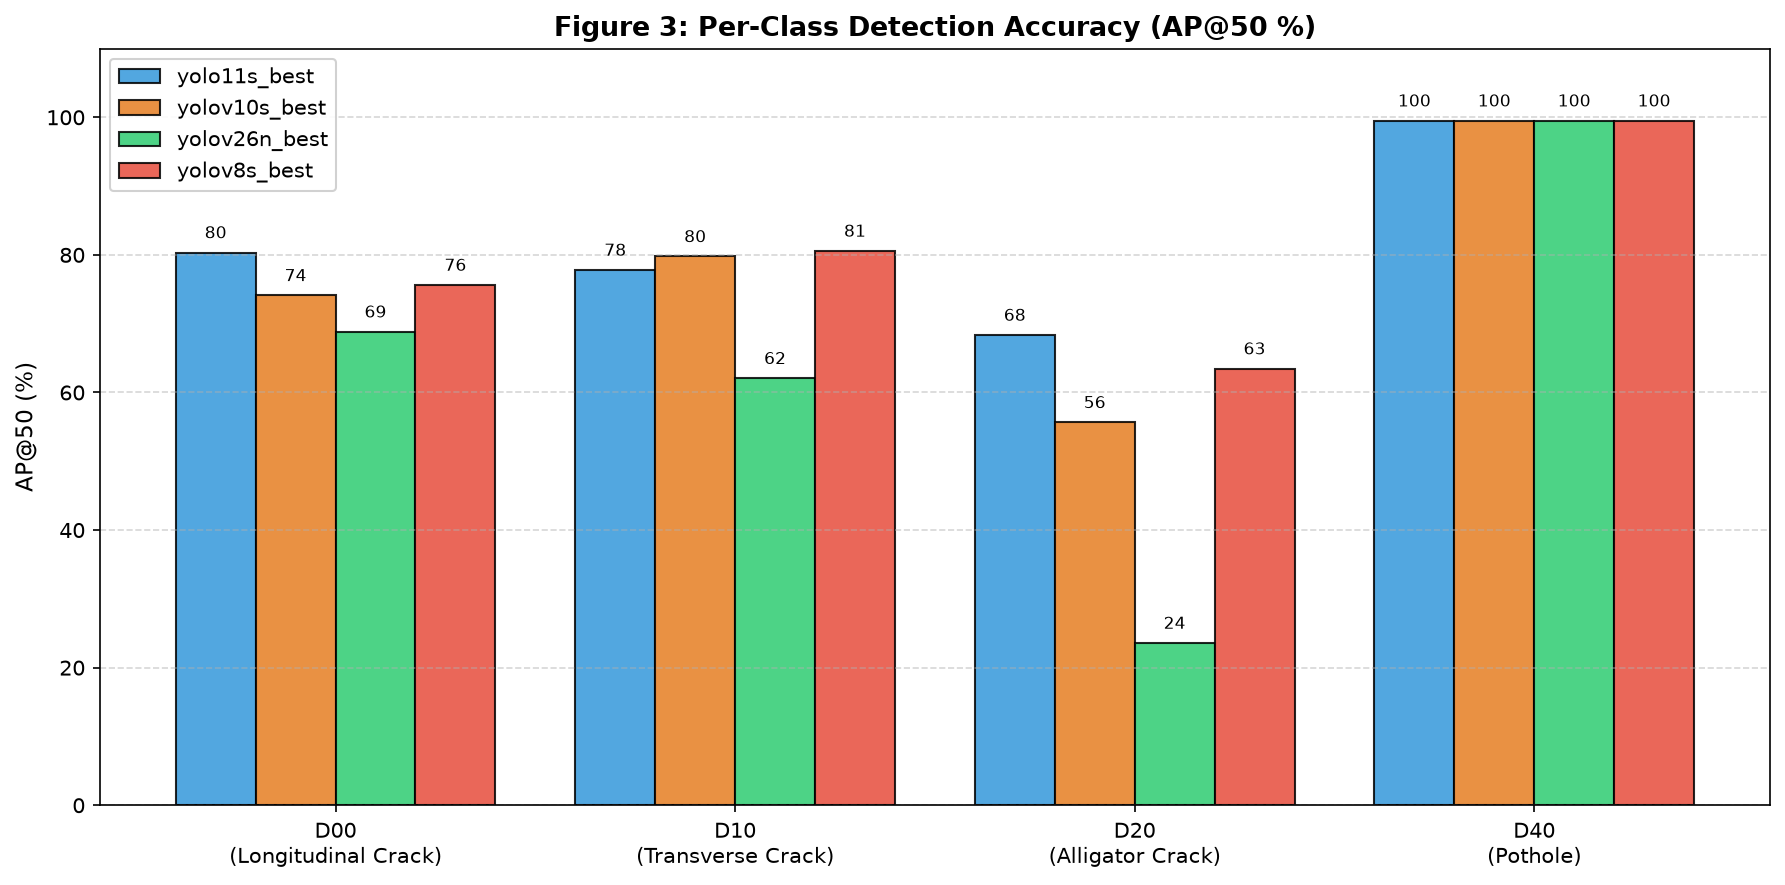

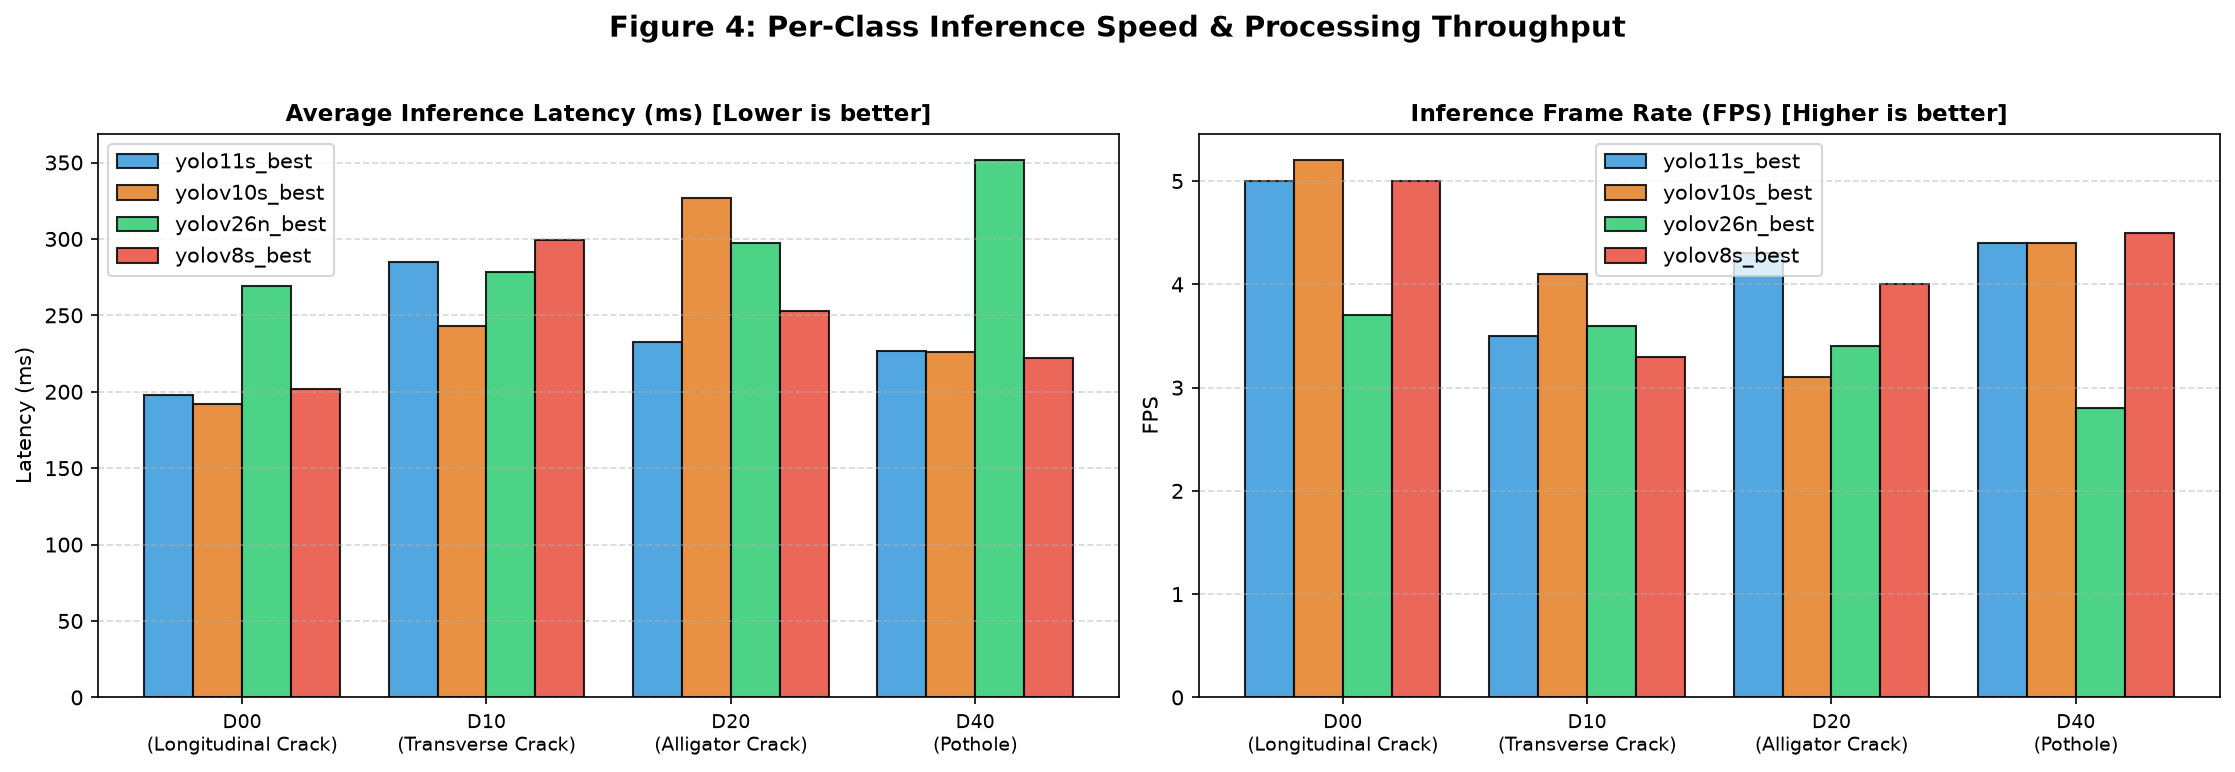

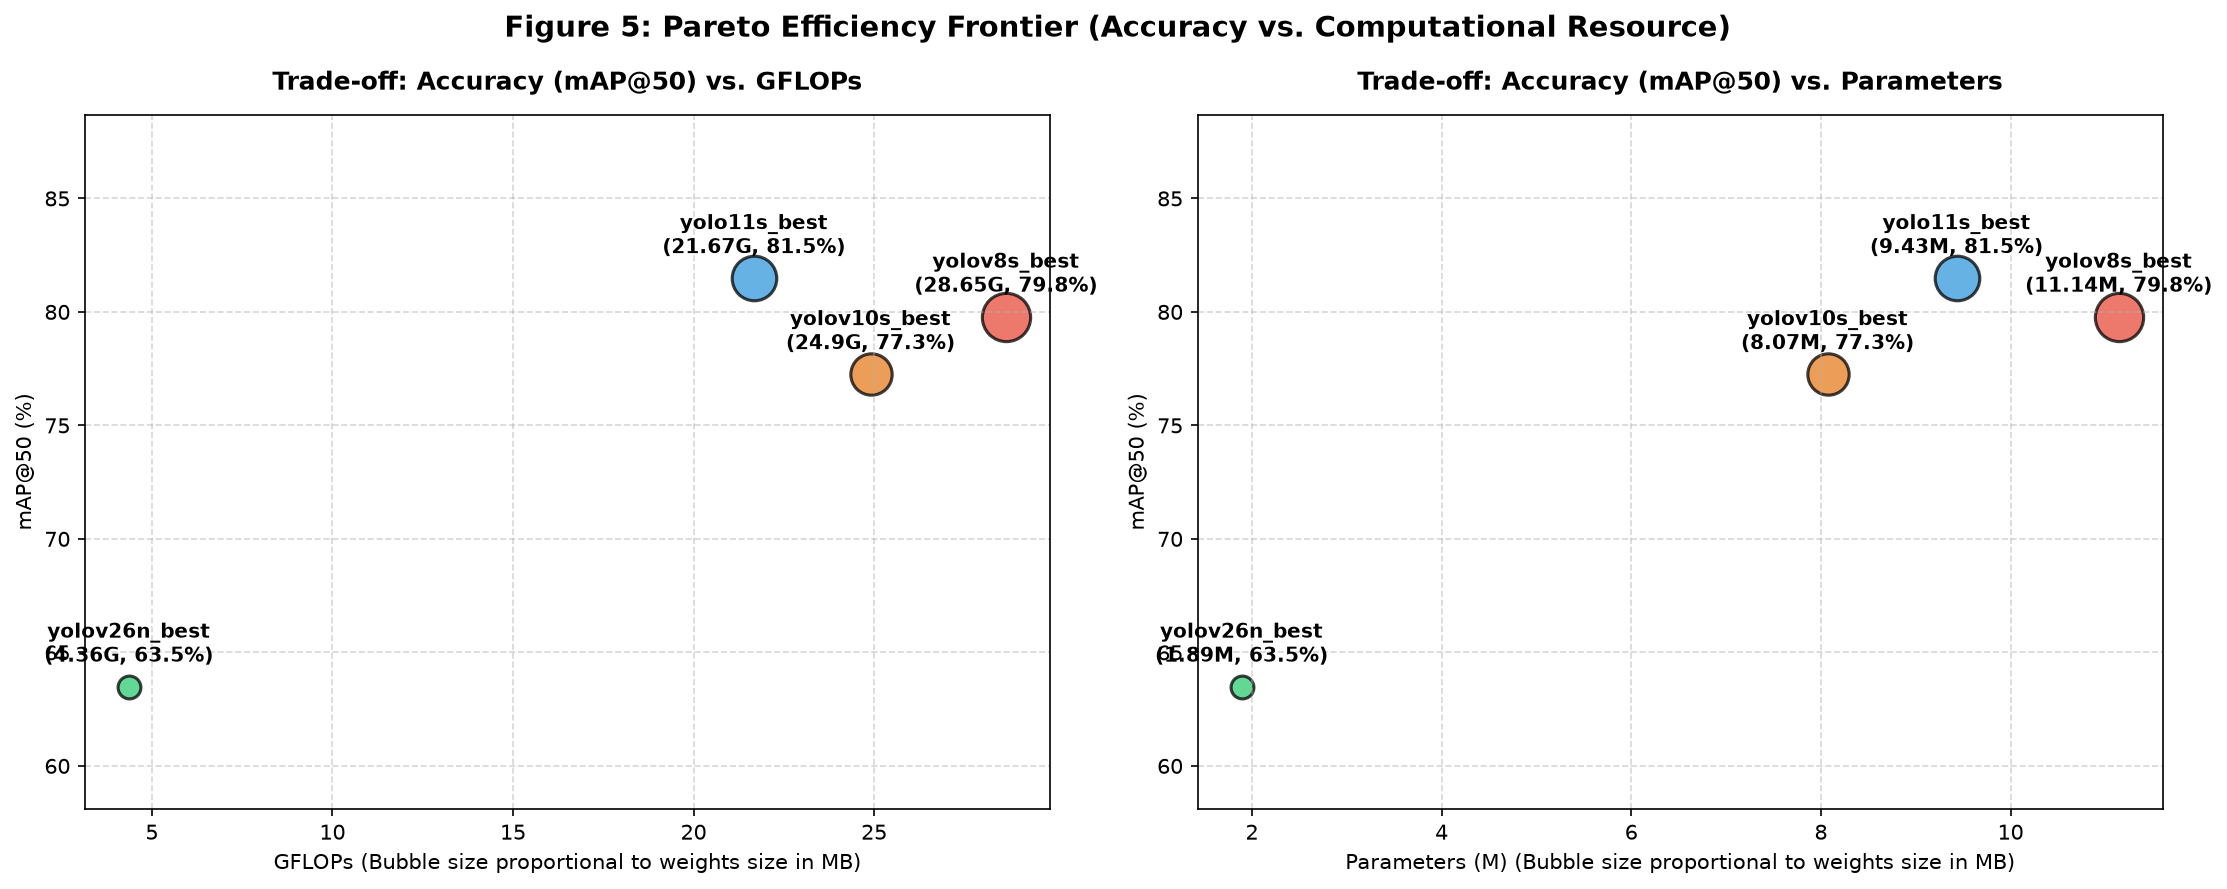

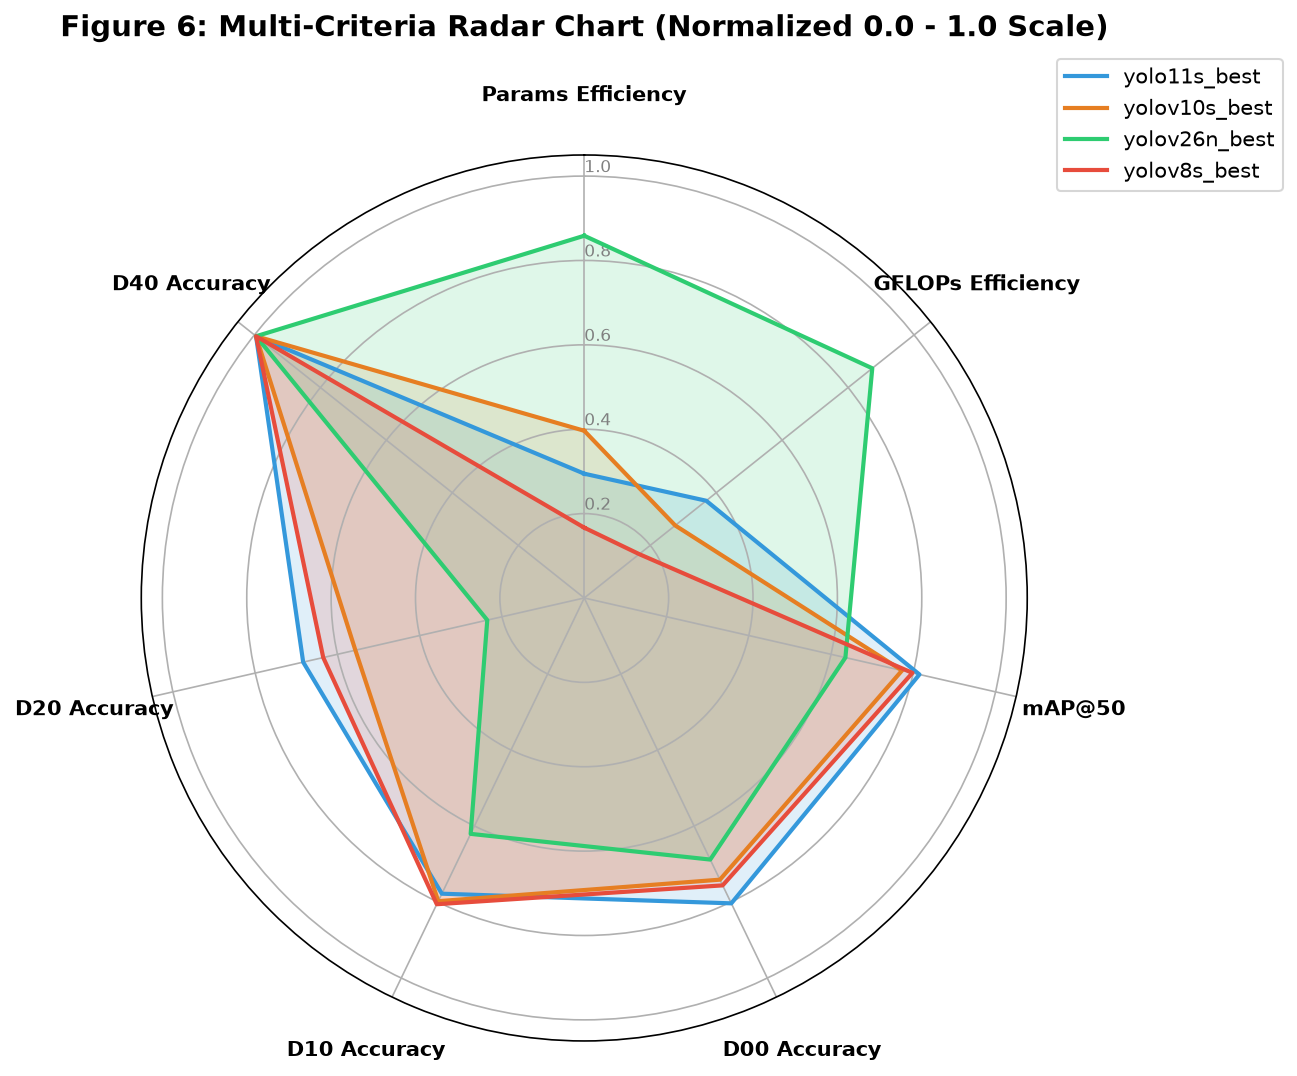

Saved 6 high-resolution visualization figures to: /Users/trietnguyen/Documents/AIL-RDD/fig


In [ ]:
PLOTS_DIR = PROJECT_ROOT / 'fig'
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

if not combined_data:
    print('Warning: No benchmark data available for visualization.')
else:
    model_labels = [d['model_name'] for d in combined_data]
    palette = ['#3498db', '#e67e22', '#2ecc71', '#e74c3c', '#9b59b6', '#1abc9c']
    model_colors = [palette[i % len(palette)] for i in range(len(combined_data))]

    # -------------------------------------------------------------
    # GENERATE STREAMLINED ARCHITECTURE DIAGRAM (YOLOV26N)
    # -------------------------------------------------------------
    def generate_yolov26n_architecture(output_path):
        """
        Publication-grade modular architecture diagram for YOLOv26n.
        3 parallel multi-scale horizontal tracks (P3, P4, P5) aligning Backbone -> Neck -> Head.
        High contrast, large fonts (titles 13-16pt, body 10.5-12pt), clean equations.
        """
        fig = plt.figure(figsize=(25, 13.5), dpi=300)
        ax = fig.add_axes([0, 0, 1, 1])
        ax.set_xlim(0, 25)
        ax.set_ylim(0, 13.5)
        ax.axis('off')
        ax.add_patch(patches.Rectangle((0, 0), 25, 13.5, facecolor='#FFFFFF'))

        # Main Figure Title
        ax.text(12.5, 13.0, 'Figure 1: Neural Network Architecture of YOLOv26n (Ours)',
                fontsize=21, fontweight='bold', ha='center', va='center', color='#0F172A')
        ax.text(12.5, 12.55, 'Streamlined Modular Design: C2f-DCNv2 Backbone, Slim-Neck (VoVGSCSP + GSConv), and GCH Detection Head on RDD2022',
                fontsize=12.5, ha='center', va='center', style='italic', color='#475569')
        ax.plot([0.6, 24.4], [12.2, 12.2], color='#E2E8F0', lw=2)

        def draw_section_card(x, y, w, h, title, title_bg='#2563EB', card_bg='#F8FAFC', border_color='#CBD5E1'):
            ax.add_patch(patches.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.10',
                                                facecolor=card_bg, edgecolor=border_color, linewidth=1.8, zorder=1))
            header_h = 0.52
            ax.add_patch(patches.FancyBboxPatch((x, y + h - header_h), w, header_h, boxstyle='round,pad=0.03',
                                                facecolor=title_bg, edgecolor='none', zorder=2))
            ax.text(x + w / 2, y + h - header_h / 2, title,
                    fontsize=12.5, fontweight='bold', ha='center', va='center', color='#FFFFFF', zorder=3)

        def draw_node(x, y, w, h, name, desc="", tensor="", bg='#FFFFFF', border='#2563EB', title_color='#0F172A', is_novel=False):
            if is_novel:
                ax.add_patch(patches.FancyBboxPatch((x - 0.05, y - 0.05), w + 0.10, h + 0.10,
                                                    boxstyle='round,pad=0.06', facecolor='none',
                                                    edgecolor='#EA580C', linewidth=2.0, linestyle='--', zorder=4))
            ax.add_patch(patches.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.06',
                                                facecolor=bg, edgecolor=border, linewidth=1.6, zorder=5))
            ax.text(x + w / 2, y + h - 0.28, name, fontsize=11.5, fontweight='bold', ha='center', va='center', color=title_color, zorder=6)
            if desc:
                ax.text(x + w / 2, y + h / 2 - 0.06, desc, fontsize=9.8, ha='center', va='center', color='#475569', zorder=6)
            if tensor:
                ax.text(x + w / 2, y + 0.20, tensor, fontsize=9.0, fontweight='bold', ha='center', va='center', color='#1E40AF',
                        bbox=dict(boxstyle='round,pad=0.2', facecolor='#EFF6FF', edgecolor='#BFDBFE', lw=0.8), zorder=6)

        def draw_arrow(x1, y1, x2, y2, color='#334155', lw=2.0, label=""):
            ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                        arrowprops=dict(arrowstyle='->', lw=lw, color=color, shrinkA=1, shrinkB=1), zorder=7)
            if label:
                mid_x = (x1 + x2) / 2
                mid_y = (y1 + y2) / 2
                ax.text(mid_x, mid_y + 0.18, label, fontsize=8.5, fontweight='bold', ha='center', va='center',
                        color='#0369A1', bbox=dict(boxstyle='round,pad=0.15', facecolor='#FFFFFF', edgecolor='#BAE6FD', lw=0.6), zorder=8)

        # Layout boundaries
        draw_section_card(0.6, 0.6, 4.6, 11.3, '1. BACKBONE: C2f-DCNv2', '#1E40AF', '#F8FAFC', '#93C5FD')
        draw_section_card(5.4, 0.6, 6.6, 11.3, '2. SLIM-NECK: FPN + PAN (GSConv & VoV)', '#065F46', '#F0FDF4', '#86EFAC')
        draw_section_card(12.2, 0.6, 5.4, 11.3, '3. DETECTION HEAD (GCHDetect)', '#991B1B', '#FEF2F2', '#FCA5A5')
        draw_section_card(17.8, 0.6, 6.6, 11.3, 'CORE ARCHITECTURAL INNOVATIONS', '#581C87', '#FAF5FF', '#D8B4FE')

        # Y-tracks for parallel alignment
        y_p3 = 7.7
        y_p4 = 4.3
        y_p5 = 0.9

        # Backbone nodes
        bx, bw, bh = 0.9, 4.0, 1.25
        draw_node(bx, 10.2, bw, 0.95, 'Input Road Image', 'RDD2022 Benchmark Dataset', '3 × 640 × 640 RGB',
                  bg='#EFF6FF', border='#3B82F6', title_color='#1D4ED8')
        draw_arrow(bx + bw / 2, 10.2, bx + bw / 2, 9.65, lw=2.2)

        draw_node(bx, 8.8, bw, 0.85, 'Stem & Stage 1 Conv', 'Conv 3×3 s=2 (P1) + Conv 3×3 s=2 (P2)', '32 × 160 × 160',
                  bg='#FFFFFF', border='#2563EB')
        draw_arrow(bx + bw / 2, 8.8, bx + bw / 2, y_p3 + bh, lw=2.2)

        draw_node(bx, y_p3, bw, bh, 'Stage 2: C2f-DCNv2 [P3]', 'Conv s=2 + Bottlenecks with DCNv2', '64 × 80 × 80  (→ P3 Neck)',
                  bg='#FFF7ED', border='#EA580C', title_color='#C2410C', is_novel=True)
        draw_arrow(bx + bw / 2, y_p3, bx + bw / 2, y_p4 + bh, lw=2.2)

        draw_node(bx, y_p4, bw, bh, 'Stage 3: C2f-DCNv2 [P4]', 'Conv s=2 + Bottlenecks with DCNv2', '128 × 40 × 40  (→ P4 Neck)',
                  bg='#FFF7ED', border='#EA580C', title_color='#C2410C', is_novel=True)
        draw_arrow(bx + bw / 2, y_p4, bx + bw / 2, y_p5 + bh + 0.35, lw=2.2)

        draw_node(bx, y_p5, bw, bh + 0.35, 'Stage 4: C2f-DCNv2 + SPPF [P5]', 'Conv s=2 + DCNv2 + Spatial Pyramid Pooling', '256 × 20 × 20  (→ P5 Neck)',
                  bg='#FFF7ED', border='#EA580C', title_color='#C2410C', is_novel=True)

        # Neck nodes
        fnx, fnw = 5.7, 2.85
        pnx, pnw = 8.85, 2.85

        draw_node(fnx, y_p5 + 0.2, fnw, bh, 'FPN Top Input', 'From Backbone SPPF', '256 × 20 × 20',
                  bg='#EDE9FE', border='#7C3AED', title_color='#6D28D9')
        draw_arrow(bx + bw, y_p5 + (bh + 0.35) / 2, fnx, y_p5 + 0.2 + bh / 2, color='#7C3AED', lw=2.2, label="P5")

        draw_node(pnx, y_p5 + 0.2, pnw, bh, 'PAN Output [P5]', 'VoVGSCSP (OSA)', '256 × 20 × 20',
                  bg='#ECFDF5', border='#059669', title_color='#047857', is_novel=True)

        draw_arrow(fnx + fnw / 2, y_p5 + 0.2 + bh, fnx + fnw / 2, y_p4, color='#2563EB', lw=2.0, label="2× Up")

        draw_node(fnx, y_p4, fnw, bh, 'FPN Fusion [P4]', 'Concat + VoVGSCSP', '128 × 40 × 40',
                  bg='#ECFDF5', border='#059669', title_color='#047857', is_novel=True)
        draw_arrow(bx + bw, y_p4 + bh / 2, fnx, y_p4 + bh / 2, color='#EA580C', lw=2.2, label="P4")

        draw_node(pnx, y_p4, pnw, bh, 'PAN Output [P4]', 'VoVGSCSP (OSA)', '128 × 40 × 40',
                  bg='#ECFDF5', border='#059669', title_color='#047857', is_novel=True)

        draw_arrow(fnx + fnw / 2, y_p4 + bh, fnx + fnw / 2, y_p3, color='#2563EB', lw=2.0, label="2× Up")

        draw_node(fnx, y_p3, fnw, bh, 'FPN Output [P3]', 'Concat + VoVGSCSP', '64 × 80 × 80',
                  bg='#ECFDF5', border='#059669', title_color='#047857', is_novel=True)
        draw_arrow(bx + bw, y_p3 + bh / 2, fnx, y_p3 + bh / 2, color='#EA580C', lw=2.2, label="P3")

        draw_node(pnx, y_p3, pnw, bh, 'PAN Input [P3]', 'VoVGSCSP (OSA)', '64 × 80 × 80',
                  bg='#ECFDF5', border='#059669', title_color='#047857', is_novel=True)

        draw_arrow(fnx + fnw, y_p3 + bh / 2, pnx, y_p3 + bh / 2, color='#059669', lw=2.2, label="P3 Bridge")
        draw_arrow(pnx + pnw / 2, y_p3, pnx + pnw / 2, y_p4 + bh, color='#059669', lw=2.0, label="GSConv s=2")
        draw_arrow(pnx + pnw / 2, y_p4, pnx + pnw / 2, y_p5 + 0.2 + bh, color='#059669', lw=2.0, label="GSConv s=2")

        # Head nodes
        hx, hw = 12.5, 4.8
        draw_node(hx, y_p3 - 0.2, hw, bh + 0.4, 'GCH Head [P3] (Small Defects)',
                  'Shared Group Conv (g=4) + Decoupled 1×1 Heads\nDetects: D00 (Longitudinal) & D10 (Transverse)',
                  'Feature: 64 × 80 × 80  |  AP50: 68.8% / 62.1%',
                  bg='#FFFFFF', border='#DC2626', title_color='#B91C1C', is_novel=True)
        draw_arrow(pnx + pnw, y_p3 + bh / 2, hx, y_p3 - 0.2 + (bh + 0.4) / 2, color='#DC2626', lw=2.2)

        draw_node(hx, y_p4 - 0.2, hw, bh + 0.4, 'GCH Head [P4] (Medium Defects)',
                  'Shared Group Conv (g=4) + Decoupled 1×1 Heads\nDetects: D10 (Transverse) & D20 (Alligator)',
                  'Feature: 128 × 40 × 40  |  AP50: 23.6%',
                  bg='#FFFFFF', border='#DC2626', title_color='#B91C1C', is_novel=True)
        draw_arrow(pnx + pnw, y_p4 + bh / 2, hx, y_p4 - 0.2 + (bh + 0.4) / 2, color='#DC2626', lw=2.2)

        draw_node(hx, y_p5, hw, bh + 0.4, 'GCH Head [P5] (Large Defects)',
                  'Shared Group Conv (g=4) + Decoupled 1×1 Heads\nDetects: D40 (Potholes) & Severe Cracks',
                  'Feature: 256 × 20 × 20  |  AP50: 99.5%',
                  bg='#FFFFFF', border='#DC2626', title_color='#B91C1C', is_novel=True)
        draw_arrow(pnx + pnw, y_p5 + 0.2 + bh / 2, hx, y_p5 + (bh + 0.4) / 2, color='#DC2626', lw=2.2)

        ax.text(hx + hw / 2, 10.5, 'Head Params Reduced by >70%\nShared Conv Trunk (g=4)',
                fontsize=11, fontweight='bold', ha='center', va='center', color='#991B1B',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='#FEF2F2', edgecolor='#FCA5A5', lw=1.2), zorder=6)

        # Innovation Spotlight Cards
        rx, rw = 18.1, 6.0

        # Card 1: C2f-DCNv2
        c1_y, c1_h = 8.1, 3.4
        ax.add_patch(patches.FancyBboxPatch((rx, c1_y), rw, c1_h, boxstyle='round,pad=0.08', facecolor='#FFFFFF', edgecolor='#EA580C', lw=1.6, zorder=4))
        ax.add_patch(patches.FancyBboxPatch((rx, c1_y + c1_h - 0.42), rw, 0.42, boxstyle='round,pad=0.02', facecolor='#FFF7ED', edgecolor='none', zorder=5))
        ax.text(rx + rw / 2, c1_y + c1_h - 0.21, 'Module 1: C2f-DCNv2 (Backbone Geometric Adaptation)', fontsize=11, fontweight='bold', ha='center', va='center', color='#C2410C', zorder=6)
        ax.text(rx + 0.35, c1_y + c1_h - 0.70, '• Replaces standard conv in YOLO bottlenecks with DCNv2', fontsize=10.2, fontweight='bold', color='#1E293B', zorder=6)
        ax.text(rx + 0.35, c1_y + c1_h - 1.10, '• Learns 2D offsets Δp_k to dynamically track tortuous cracks', fontsize=10, color='#334155', zorder=6)
        ax.text(rx + 0.35, c1_y + c1_h - 1.50, '• Modulation masks Δm_k ∈ [0, 1] suppress noisy road texture', fontsize=10, color='#334155', zorder=6)
        ax.text(rx + rw / 2, c1_y + 0.70, r"$y(p) = \sum_{k=1}^K w_k \cdot x(p + p_k + \Delta p_k) \cdot \Delta m_k$",
                fontsize=11, color='#0F172A', ha='center', bbox=dict(boxstyle='round,pad=0.25', facecolor='#FFF7ED', edgecolor='#FDBA74'), zorder=6)

        # Card 2: Slim-Neck
        c2_y, c2_h = 4.4, 3.4
        ax.add_patch(patches.FancyBboxPatch((rx, c2_y), rw, c2_h, boxstyle='round,pad=0.08', facecolor='#FFFFFF', edgecolor='#059669', lw=1.6, zorder=4))
        ax.add_patch(patches.FancyBboxPatch((rx, c2_y + c2_h - 0.42), rw, 0.42, boxstyle='round,pad=0.02', facecolor='#ECFDF5', edgecolor='none', zorder=5))
        ax.text(rx + rw / 2, c2_y + c2_h - 0.21, 'Module 2: Slim-Neck (VoVGSCSP & GSConv)', fontsize=11, fontweight='bold', ha='center', va='center', color='#047857', zorder=6)
        ax.text(rx + 0.35, c2_y + c2_h - 0.70, '• GSConv: Conv 1×1 + Depthwise Conv 5×5 + Channel Shuffle', fontsize=10.2, fontweight='bold', color='#1E293B', zorder=6)
        ax.text(rx + 0.35, c2_y + c2_h - 1.10, '• Preserves non-linear crack features with low computational load', fontsize=10, color='#334155', zorder=6)
        ax.text(rx + 0.35, c2_y + c2_h - 1.50, '• VoVGSCSP: One-Shot Aggregation (OSA) multi-scale fusion', fontsize=10, color='#334155', zorder=6)
        ax.text(rx + 0.35, c2_y + c2_h - 1.95, '• Efficiency Gain: Cuts Neck FLOPs by >79% vs Standard CSP', fontsize=10.2, fontweight='bold', color='#059669', zorder=6)
        ax.text(rx + rw / 2, c2_y + 0.50, 'Input X ──► [Conv 1×1] + [DWConv 5×5] ──► Shuffle ──► OSA',
                fontsize=9.5, fontweight='bold', color='#047857', ha='center', bbox=dict(boxstyle='round,pad=0.2', facecolor='#F0FDF4', edgecolor='#86EFAC'), zorder=6)

        # Card 3: GCHDetect
        c3_y, c3_h = 0.9, 3.2
        ax.add_patch(patches.FancyBboxPatch((rx, c3_y), rw, c3_h, boxstyle='round,pad=0.08', facecolor='#FFFFFF', edgecolor='#DC2626', lw=1.6, zorder=4))
        ax.add_patch(patches.FancyBboxPatch((rx, c3_y + c3_h - 0.42), rw, 0.42, boxstyle='round,pad=0.02', facecolor='#FEF2F2', edgecolor='none', zorder=5))
        ax.text(rx + rw / 2, c3_y + c3_h - 0.21, 'Module 3: GCHDetect (Grouped Conv Detection Head)', fontsize=11, fontweight='bold', ha='center', va='center', color='#B91C1C', zorder=6)
        ax.text(rx + 0.35, c3_y + c3_h - 0.70, '• Shared Feature Trunk with Grouped Convolutions (g = 4)', fontsize=10.2, fontweight='bold', color='#1E293B', zorder=6)
        ax.text(rx + 0.35, c3_y + c3_h - 1.10, '• Shares low-level feature extraction for both Cls & Bbox tasks', fontsize=10, color='#334155', zorder=6)
        ax.text(rx + 0.35, c3_y + c3_h - 1.50, '• Decoupled 1×1 Conv prediction heads for bounding box & classes', fontsize=10, color='#334155', zorder=6)
        ax.text(rx + 0.35, c3_y + c3_h - 1.95, '• Parameter Reduction: -22.28% Total Params, >70% Head Weights', fontsize=10.2, fontweight='bold', color='#DC2626', zorder=6)
        ax.text(rx + rw / 2, c3_y + 0.45, r"$\text{FLOPs}_{\text{GCH}} = \frac{1}{g} \cdot \text{FLOPs}_{\text{standard}} \quad (g = 4)$",
                fontsize=10.5, color='#0F172A', ha='center', bbox=dict(boxstyle='round,pad=0.2', facecolor='#FEF2F2', edgecolor='#FCA5A5'), zorder=6)

        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(output_path, dpi=300, bbox_inches='tight', pad_inches=0.1)
        plt.close(fig)

    # -------------------------------------------------------------
    # GENERATE STANDALONE INFERENCE PIPELINE DIAGRAM (YOLOV26N)
    # -------------------------------------------------------------
    def generate_yolov26n_pipeline(output_path):
        """
        Publication-quality standalone inference pipeline diagram for YOLOv26n.
        Large typography, clean horizontal layout without embedding architecture.
        Generous spacing, concise bullet points that fit perfectly inside cards.
        Centered transition arrows and tensor flow badges.
        """
        fig = plt.figure(figsize=(23, 9.5), dpi=300)
        ax = fig.add_axes([0, 0, 1, 1])
        ax.set_xlim(0, 23)
        ax.set_ylim(0, 9.5)
        ax.axis('off')
        ax.add_patch(patches.Rectangle((0, 0), 23, 9.5, facecolor='#FFFFFF'))

        # Header
        ax.text(11.5, 9.0, 'Figure 2: End-to-End Inference & Evaluation Pipeline of YOLOv26n (Ours)',
                fontsize=21, fontweight='bold', ha='center', va='center', color='#0F172A')
        ax.text(11.5, 8.55, 'Tailored Road Damage Detection Workflow on RDD2022 Benchmark Dataset (4 Defect Categories)',
                fontsize=12.5, ha='center', va='center', style='italic', color='#475569')
        ax.plot([0.8, 22.2], [8.2, 8.2], color='#E2E8F0', lw=2)

        stages = [
            {
                'num': 'STAGE 1',
                'title': 'Input & Preprocess',
                'badge_bg': '#2563EB',
                'box_bg': '#EFF6FF',
                'border': '#3B82F6',
                'bullets': [
                    ('• RDD2022 Dataset', 'Pavement defect benchmark'),
                    ('• Resolution', '3 × 640 × 640 RGB image'),
                    ('• Preprocessing', 'Letterbox resize (stride 32)'),
                    ('• Tensor Normalization', 'Pixel scaling into [0, 1] range'),
                    ('• Target Defect Set', '4 damage classes (D00-D40)')
                ],
                'x': 0.8, 'w': 3.5
            },
            {
                'num': 'STAGE 2',
                'title': 'Feature Extraction',
                'badge_bg': '#EA580C',
                'box_bg': '#FFF7ED',
                'border': '#F97316',
                'bullets': [
                    ('• Backbone Network', 'C2f-DCNv2 architecture'),
                    ('• Deformable Conv v2', 'Learns 2D offsets Δp & masks Δm'),
                    ('• Geometric Adaptation', 'Dynamically follows crack paths'),
                    ('• Noise Suppression', 'Suppresses rough asphalt noise'),
                    ('• Multi-Scale Pyramids', 'Outputs: P3, P4, P5 (+ SPPF)')
                ],
                'x': 5.1, 'w': 3.5
            },
            {
                'num': 'STAGE 3',
                'title': 'Multi-Scale Fusion',
                'badge_bg': '#059669',
                'box_bg': '#ECFDF5',
                'border': '#10B981',
                'bullets': [
                    ('• Slim-Neck Design', 'GSConv + VoVGSCSP modules'),
                    ('• Bidirectional Paths', 'Top-Down FPN + Bottom-Up PAN'),
                    ('• Channel Shuffle', 'Conv 1×1 + DWConv 5×5 mixing'),
                    ('• One-Shot Aggregation', 'VoVGSCSP preserves fine details'),
                    ('• High Efficiency', 'Cuts Neck FLOPs by >79% vs CSP')
                ],
                'x': 9.4, 'w': 3.5
            },
            {
                'num': 'STAGE 4',
                'title': 'GCH Detection Head',
                'badge_bg': '#DC2626',
                'box_bg': '#FEF2F2',
                'border': '#EF4444',
                'bullets': [
                    ('• Grouped Conv Trunk', 'Shared feature trunk (g = 4)'),
                    ('• Dual-Task Feature', 'Shared for Cls & Bbox branches'),
                    ('• Decoupled Heads', '1×1 Conv classification & regression'),
                    ('• Multi-Scale Detectors', 'Dedicated heads at P3, P4, P5'),
                    ('• Lightweight Head', '>70% reduction in head weights')
                ],
                'x': 13.7, 'w': 3.5
            },
            {
                'num': 'STAGE 5',
                'title': 'Output & Evaluation',
                'badge_bg': '#7C3AED',
                'box_bg': '#F5F3FF',
                'border': '#8B5CF6',
                'bullets': [
                    ('• Post-Processing', 'NMS (IoU 0.45) & Conf >= 0.25'),
                    ('• D00: Longitudinal Crack', 'AP@50 = 68.8% (Linear defect)'),
                    ('• D10: Transverse Crack', 'AP@50 = 62.1% (Perpendicular)'),
                    ('• D20: Alligator Crack', 'AP@50 = 23.6% (Mesh defect)'),
                    ('• D40: Pothole (Severe)', 'AP@50 = 99.5% (Cavity defect)')
                ],
                'x': 18.0, 'w': 3.5
            },
        ]

        box_y, box_h = 2.4, 5.5

        for st in stages:
            bx = st['x']
            bw = st['w']

            ax.add_patch(patches.FancyBboxPatch((bx, box_y), bw, box_h, boxstyle='round,pad=0.08',
                                                facecolor=st['box_bg'], edgecolor=st['border'], linewidth=2.0))
            badge_h = 0.60
            ax.add_patch(patches.FancyBboxPatch((bx, box_y + box_h - badge_h), bw, badge_h, boxstyle='round,pad=0.02',
                                                facecolor=st['badge_bg'], edgecolor='none'))
            ax.text(bx + bw / 2, box_y + box_h - badge_h / 2, f"{st['num']}: {st['title']}",
                    fontsize=12, fontweight='bold', ha='center', va='center', color='#FFFFFF')

            start_y = box_y + box_h - 1.05
            block_gap = 0.88
            for idx, (title, desc) in enumerate(st['bullets']):
                curr_y = start_y - idx * block_gap
                ax.text(bx + 0.25, curr_y, title, fontsize=10.5, fontweight='bold', color='#0F172A', va='center')
                ax.text(bx + 0.45, curr_y - 0.32, desc, fontsize=9.2, color='#475569', va='center')

        tensor_labels = [
            'Tensor: [3, 640, 640]',
            'Pyramids {P3, P4, P5}',
            'Neck Fused {N3, N4, N5}',
            'Raw Predictions'
        ]
        for i in range(4):
            x_start = stages[i]['x'] + stages[i]['w'] + 0.08
            x_end = stages[i + 1]['x'] - 0.08
            arrow_y = box_y + box_h - 0.30
            ax.annotate('', xy=(x_end, arrow_y), xytext=(x_start, arrow_y),
                        arrowprops=dict(arrowstyle='->', lw=2.5, color='#334155', shrinkA=1, shrinkB=1), zorder=8)
            mid_x = (x_start + x_end) / 2
            ax.text(mid_x, arrow_y + 0.32, tensor_labels[i], fontsize=8.0, fontweight='bold', ha='center', va='center',
                    color='#1E40AF', bbox=dict(boxstyle='round,pad=0.22', facecolor='#EFF6FF', edgecolor='#BFDBFE', lw=0.8), zorder=9)

        # Efficiency Summary Banner
        banner_y, banner_h = 0.65, 1.25
        ax.add_patch(patches.FancyBboxPatch((0.8, banner_y), 20.7, banner_h, boxstyle='round,pad=0.10',
                                            facecolor='#F8FAFC', edgecolor='#CBD5E1', linewidth=1.8))
        
        ax.text(1.2, banner_y + banner_h / 2, 'YOLOv26n (Ours) Key Advantages vs Baseline YOLOv8s:',
                fontsize=12, fontweight='bold', color='#0F172A', va='center')
        
        metric_badges = [
            ('1.89 M Params', '(-83.0% vs YOLOv8s)', '#2563EB'),
            ('4.36 GFLOPs', '(-84.8% vs YOLOv8s)', '#059669'),
            ('3.83 MB Weights', '(L2/L3 Cache Fit)', '#7C3AED'),
            ('63.49% mAP@50', '(Benchmark AP)', '#EA580C'),
            ('282.7 ms Latency', '(Edge Ready)', '#DC2626')
        ]
        start_mx = 10.2
        for label, sublabel, color in metric_badges:
            ax.text(start_mx, banner_y + banner_h / 2 + 0.22, label, fontsize=11, fontweight='bold', color=color, ha='center', va='center')
            ax.text(start_mx, banner_y + banner_h / 2 - 0.22, sublabel, fontsize=9.2, color='#64748B', ha='center', va='center')
            start_mx += 2.25

        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(output_path, dpi=300, bbox_inches='tight', pad_inches=0.1)
        plt.close(fig)

    # -------------------------------------------------------------
    # FIGURE 1: YOLOV26N NEURAL NETWORK ARCHITECTURE
    # -------------------------------------------------------------
    arch_file = PLOTS_DIR / 'f1_architecture_yolov26n.png'
    generate_yolov26n_architecture(arch_file)
    img_arch = mpimg.imread(str(arch_file))
    fig_arch_show = plt.figure(figsize=(15, 8.1), dpi=150)
    plt.imshow(img_arch)
    plt.axis('off')
    plt.title('Figure 1: Neural Network Architecture of YOLOv26n (Ours)', fontsize=13, fontweight='bold', pad=10)
    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # FIGURE 2: YOLOV26N INFERENCE & EVALUATION PIPELINE
    # -------------------------------------------------------------
    pipe_file = PLOTS_DIR / 'f2_pipeline_yolov26n.png'
    generate_yolov26n_pipeline(pipe_file)
    img_pipe = mpimg.imread(str(pipe_file))
    fig_pipe_show = plt.figure(figsize=(15, 6.2), dpi=150)
    plt.imshow(img_pipe)
    plt.axis('off')
    plt.title('Figure 2: End-to-End Inference & Evaluation Pipeline of YOLOv26n (Ours)', fontsize=13, fontweight='bold', pad=10)
    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # FIGURE 3: CORE METRICS COMPARISON
    # -------------------------------------------------------------
    fig_core, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=150)
    max_param = max([d['params_m'] for d in combined_data], default=1.0) or 1.0
    max_flop = max([d['gflops'] for d in combined_data], default=1.0) or 1.0

    # Parameters
    axes[0].bar(model_labels, [d['params_m'] for d in combined_data], color=model_colors, edgecolor='black', alpha=0.85)
    axes[0].set_title('Parameters (Millions) [Lower is better]', fontsize=11, fontweight='bold')
    axes[0].set_ylabel('Params (M)')
    axes[0].grid(axis='y', linestyle='--', alpha=0.5)
    for i, v in enumerate([d['params_m'] for d in combined_data]):
        axes[0].text(i, v + max_param * 0.02, f'{v:.2f}M', ha='center', fontsize=10, fontweight='bold')

    # GFLOPs
    axes[1].bar(model_labels, [d['gflops'] for d in combined_data], color=model_colors, edgecolor='black', alpha=0.85)
    axes[1].set_title('Computational Cost (GFLOPs @ 640x640) [Lower is better]', fontsize=11, fontweight='bold')
    axes[1].set_ylabel('GFLOPs')
    axes[1].grid(axis='y', linestyle='--', alpha=0.5)
    for i, v in enumerate([d['gflops'] for d in combined_data]):
        axes[1].text(i, v + max_flop * 0.02, f'{v:.2f}', ha='center', fontsize=10, fontweight='bold')

    # mAP@50
    axes[2].bar(model_labels, [d['map50'] for d in combined_data], color=model_colors, edgecolor='black', alpha=0.85)
    axes[2].set_title('Detection Accuracy (mAP@50 %) [Higher is better]', fontsize=11, fontweight='bold')
    axes[2].set_ylabel('mAP@50 (%)')
    axes[2].set_ylim(0, 100)
    axes[2].grid(axis='y', linestyle='--', alpha=0.5)
    for i, v in enumerate([d['map50'] for d in combined_data]):
        axes[2].text(i, v + 2, f'{v:.1f}%', ha='center', fontsize=10, fontweight='bold')

    plt.suptitle('Figure 3: Overall Model Efficiency & Detection Accuracy Comparison', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    fig_core.savefig(PLOTS_DIR / 'f3_core_metrics.png', bbox_inches='tight', dpi=300)
    plt.show()

    # -------------------------------------------------------------
    # FIGURE 4: PER-CLASS DETECTION ACCURACY (AP@50 %)
    # -------------------------------------------------------------
    fig_ap = plt.figure(figsize=(12, 6), dpi=150)
    x = np.arange(len(CLASS_NAMES))
    width = 0.8 / max(1, len(combined_data))

    for idx, d in enumerate(combined_data):
        ap_vals = [d['ap50_per_class'].get(c, 0.0) for c in CLASS_NAMES]
        offset = (idx - (len(combined_data) - 1) / 2) * width
        bars = plt.bar(x + offset, ap_vals, width, label=d['model_name'], color=model_colors[idx], edgecolor='black', alpha=0.85)
        for bar in bars:
            h = bar.get_height()
            if h > 0:
                plt.text(bar.get_x() + bar.get_width() / 2, h + 1.5, f'{h:.0f}', ha='center', va='bottom', fontsize=8)

    plt.title('Figure 4: Per-Class Detection Accuracy (AP@50 %)', fontsize=13, fontweight='bold')
    plt.xticks(x, [f'{c}\n({CLASS_LABELS[c]})' for c in CLASS_NAMES], fontsize=10)
    plt.ylabel('AP@50 (%)', fontsize=11)
    plt.ylim(0, 110)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.legend(frameon=True, facecolor='white', framealpha=0.9)
    plt.tight_layout()
    fig_ap.savefig(PLOTS_DIR / 'f4_per_class_ap.png', bbox_inches='tight', dpi=300)
    plt.show()

    # -------------------------------------------------------------
    # FIGURE 5: PER-CLASS INFERENCE SPEED & THROUGHPUT
    # -------------------------------------------------------------
    fig_spd, (ax_lat, ax_fps) = plt.subplots(1, 2, figsize=(15, 5), dpi=150)

    for idx, d in enumerate(combined_data):
        sp = d['speed_per_class']
        lat_vals = [sp.get(c, {}).get('latency_ms', 0.0) for c in CLASS_NAMES]
        fps_vals = [sp.get(c, {}).get('fps', 0.0) for c in CLASS_NAMES]
        offset = (idx - (len(combined_data) - 1) / 2) * width
        ax_lat.bar(x + offset, lat_vals, width, label=d['model_name'], color=model_colors[idx], edgecolor='black', alpha=0.85)
        ax_fps.bar(x + offset, fps_vals, width, label=d['model_name'], color=model_colors[idx], edgecolor='black', alpha=0.85)

    ax_lat.set_title('Average Inference Latency (ms) [Lower is better]', fontsize=11, fontweight='bold')
    ax_lat.set_xticks(x)
    ax_lat.set_xticklabels([f'{c}\n({CLASS_LABELS[c]})' for c in CLASS_NAMES], fontsize=9)
    ax_lat.set_ylabel('Latency (ms)')
    ax_lat.grid(axis='y', linestyle='--', alpha=0.5)
    ax_lat.legend()

    ax_fps.set_title('Inference Frame Rate (FPS) [Higher is better]', fontsize=11, fontweight='bold')
    ax_fps.set_xticks(x)
    ax_fps.set_xticklabels([f'{c}\n({CLASS_LABELS[c]})' for c in CLASS_NAMES], fontsize=9)
    ax_fps.set_ylabel('FPS')
    ax_fps.grid(axis='y', linestyle='--', alpha=0.5)
    ax_fps.legend()

    plt.suptitle('Figure 5: Per-Class Inference Speed & Processing Throughput', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    fig_spd.savefig(PLOTS_DIR / 'f5_speed_comparison.png', bbox_inches='tight', dpi=300)
    plt.show()

    # -------------------------------------------------------------
    # FIGURE 6: PARETO EFFICIENCY FRONTIER
    # -------------------------------------------------------------
    fig_pareto, (ax_p1, ax_p2) = plt.subplots(1, 2, figsize=(15, 6), dpi=150)
    all_map = [d['map50'] for d in combined_data]
    min_m = min(all_map) if all_map else 0.0
    max_m = max(all_map) if all_map else 100.0
    y_span = max(6.0, max_m - min_m)

    for idx, d in enumerate(combined_data):
        s = max(120.0, d['size_mb'] * 25.0)
        ax_p1.scatter(d['gflops'], d['map50'], s=s, color=model_colors[idx], alpha=0.75, edgecolors='black', linewidth=1.5)
        ax_p1.annotate(f"{d['model_name']}\n({d['gflops']}G, {d['map50']:.1f}%)",
                       (d['gflops'], d['map50']), textcoords='offset points', xytext=(0, 12), ha='center', fontsize=9.5, fontweight='bold')

        ax_p2.scatter(d['params_m'], d['map50'], s=s, color=model_colors[idx], alpha=0.75, edgecolors='black', linewidth=1.5)
        ax_p2.annotate(f"{d['model_name']}\n({d['params_m']}M, {d['map50']:.1f}%)",
                       (d['params_m'], d['map50']), textcoords='offset points', xytext=(0, 12), ha='center', fontsize=9.5, fontweight='bold')

    ax_p1.set_ylim(max(0.0, min_m - y_span * 0.3), min(100.0, max_m + y_span * 0.4))
    ax_p2.set_ylim(max(0.0, min_m - y_span * 0.3), min(100.0, max_m + y_span * 0.4))
    ax_p1.set_title('Trade-off: Accuracy (mAP@50) vs. GFLOPs', fontsize=12, fontweight='bold', pad=12)
    ax_p1.set_xlabel('GFLOPs (Bubble size proportional to weights size in MB)', fontsize=10)
    ax_p1.set_ylabel('mAP@50 (%)', fontsize=10)
    ax_p1.grid(True, linestyle='--', alpha=0.5)

    ax_p2.set_title('Trade-off: Accuracy (mAP@50) vs. Parameters', fontsize=12, fontweight='bold', pad=12)
    ax_p2.set_xlabel('Parameters (M) (Bubble size proportional to weights size in MB)', fontsize=10)
    ax_p2.set_ylabel('mAP@50 (%)', fontsize=10)
    ax_p2.grid(True, linestyle='--', alpha=0.5)

    plt.suptitle('Figure 6: Pareto Efficiency Frontier (Accuracy vs. Computational Resource)', fontsize=14, fontweight='bold', y=0.98)
    plt.tight_layout()
    fig_pareto.savefig(PLOTS_DIR / 'f6_pareto_tradeoff.png', bbox_inches='tight', dpi=300)
    plt.show()

    # -------------------------------------------------------------
    # FIGURE 7: MULTI-DIMENSIONAL RADAR EVALUATION
    # -------------------------------------------------------------
    radar_categories = ['Params Efficiency', 'GFLOPs Efficiency', 'mAP@50', 'D00 Accuracy', 'D10 Accuracy', 'D20 Accuracy', 'D40 Accuracy']
    N = len(radar_categories)
    angles = [n / float(N) * 2 * np.pi for n in range(N)]
    angles += angles[:1]

    fig_radar, ax_r = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True), dpi=150)

    for idx, d in enumerate(combined_data):
        p_eff = 1.0 - (d['params_m'] / (max_param * 1.2))
        g_eff = 1.0 - (d['gflops'] / (max_flop * 1.2))
        m50_norm = d['map50'] / 100.0
        d00_norm = d['ap50_per_class'].get('D00', 0.0) / 100.0
        d10_norm = d['ap50_per_class'].get('D10', 0.0) / 100.0
        d20_norm = d['ap50_per_class'].get('D20', 0.0) / 100.0
        d40_norm = d['ap50_per_class'].get('D40', 0.0) / 100.0

        values = [p_eff, g_eff, m50_norm, d00_norm, d10_norm, d20_norm, d40_norm]
        values += values[:1]
        ax_r.plot(angles, values, linewidth=2, linestyle='solid', label=d['model_name'], color=model_colors[idx])
        ax_r.fill(angles, values, color=model_colors[idx], alpha=0.15)

    ax_r.set_theta_offset(np.pi / 2)
    ax_r.set_theta_direction(-1)
    ax_r.tick_params(pad=18)
    plt.xticks(angles[:-1], radar_categories, fontsize=10, fontweight='bold')
    ax_r.set_rlabel_position(0)
    plt.yticks([0.2, 0.4, 0.6, 0.8, 1.0], ['0.2', '0.4', '0.6', '0.8', '1.0'], color='grey', size=8)
    plt.ylim(0, 1.05)
    plt.title('Figure 7: Multi-Criteria Radar Chart (Normalized 0.0 - 1.0 Scale)', fontsize=14, fontweight='bold', y=1.12)
    plt.legend(loc='upper right', bbox_to_anchor=(1.30, 1.12), fontsize=10)
    plt.tight_layout()
    fig_radar.savefig(PLOTS_DIR / 'f7_radar_chart.png', bbox_inches='tight', dpi=300)
    plt.show()
    print(f'Saved 7 high-resolution visualization figures (f1 - f7) to: {PLOTS_DIR}')


## 5. Summary & Export


In [15]:
print('=' * 115)
print('ROAD DAMAGE DETECTION (RDD) BENCHMARK SUMMARY TABLE')
print('=' * 115)
header = f"{'Model':<16} | {'Params (M)':<10} | {'GFLOPs':<8} | {'mAP@50 (%)':<11} | {'D00 (%)':<8} | {'D10 (%)':<8} | {'D20 (%)':<8} | {'D40 (%)':<8} | {'Latency':<8} | {'FPS':<6}"
print(header)
print('-' * 115)
for d in combined_data:
    pc = d['ap50_per_class']
    row_str = (
        f"{d['model_name']:<16} | "
        f"{d['params_m']:>10.2f} | "
        f"{d['gflops']:>8.2f} | "
        f"{d['map50']:>11.2f} | "
        f"{pc.get('D00', 0.0):>8.2f} | "
        f"{pc.get('D10', 0.0):>8.2f} | "
        f"{pc.get('D20', 0.0):>8.2f} | "
        f"{pc.get('D40', 0.0):>8.2f} | "
        f"{d['avg_latency_ms']:>6.1f}ms | "
        f"{d['avg_fps']:>5.1f}"
    )
    print(row_str)
print('=' * 115)

# Export CSV file
csv_path = (PROJECT_ROOT / 'benchmark' / 'benchmark_results.csv') if (PROJECT_ROOT / 'benchmark').exists() else (PROJECT_ROOT / 'benchmark_results.csv')
fieldnames = [
    'model_name', 'params_m', 'gflops', 'size_mb', 'map50', 'map50_95', 'precision', 'recall',
    'D00_ap50', 'D10_ap50', 'D20_ap50', 'D40_ap50', 'avg_latency_ms', 'avg_fps'
]
with open(csv_path, 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    for d in combined_data:
        pc = d['ap50_per_class']
        writer.writerow({
            'model_name': d['model_name'],
            'params_m': d['params_m'],
            'gflops': d['gflops'],
            'size_mb': d['size_mb'],
            'map50': d['map50'],
            'map50_95': d['map50_95'],
            'precision': d['precision'],
            'recall': d['recall'],
            'D00_ap50': pc.get('D00', 0.0),
            'D10_ap50': pc.get('D10', 0.0),
            'D20_ap50': pc.get('D20', 0.0),
            'D40_ap50': pc.get('D40', 0.0),
            'avg_latency_ms': d['avg_latency_ms'],
            'avg_fps': d['avg_fps'],
        })
print(f'Saved benchmark results to CSV: {csv_path}')

# Export JSON file
json_path = (PROJECT_ROOT / 'benchmark' / 'benchmark_results.json') if (PROJECT_ROOT / 'benchmark').exists() else (PROJECT_ROOT / 'benchmark_results.json')
with open(json_path, 'w', encoding='utf-8') as f:
    json.dump(combined_data, f, indent=2, ensure_ascii=False)
print(f'Saved detailed results to JSON: {json_path}')


ROAD DAMAGE DETECTION (RDD) BENCHMARK SUMMARY TABLE
Model            | Params (M) | GFLOPs   | mAP@50 (%)  | D00 (%)  | D10 (%)  | D20 (%)  | D40 (%)  | Latency  | FPS   
-------------------------------------------------------------------------------------------------------------------
yolo11s_best     |       9.43 |    21.67 |       81.49 |    80.34 |    77.80 |    68.34 |    99.50 |  294.0ms |   3.4
yolov10s_best    |       8.07 |    24.90 |       77.26 |    74.11 |    79.77 |    55.65 |    99.50 |  273.9ms |   3.7
yolov26n_best    |       1.89 |     4.36 |       63.49 |    68.82 |    62.06 |    23.58 |    99.50 |  282.7ms |   3.5
yolov8s_best     |      11.14 |    28.65 |       79.79 |    75.61 |    80.57 |    63.46 |    99.50 |  297.2ms |   3.4
Saved benchmark results to CSV: /Users/trietnguyen/Documents/AIL-RDD/benchmark_results.csv
Saved detailed results to JSON: /Users/trietnguyen/Documents/AIL-RDD/benchmark_results.json
